# Fig 2a: Processor power over time (data-center parts only)

Supports Section 2.1, paragraph 1: processor power rises over time, and AI accelerators sit at the upper end.

**Sources**
- AI accelerators, 2016 onward: Epoch AI `ml_hardware.csv`
- Data-center GPUs before 2016 (Tesla, FirePro S): `chip_dataset_2026.csv`
- Server CPUs to Jan 2024: `chip_dataset_2026.csv`
- Server CPUs 2024 onward: `Data/generated/processors_extra.csv` (manual; values marked `~` still need checking)

**Filters:** consumer and workstation GPUs (GeForce, Quadro, RTX A-series, Titan, Radeon RX) and desktop or edge Xeons (W, E3, E, D) are removed. Power is the manufacturer-reported TDP/TGP as published. We don't convert between power metrics.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

DATA = Path('../Data')
OUT = Path('../figures'); OUT.mkdir(exist_ok=True)

# Reference categorical palette, slots 1-2 (validated all-pairs)
C_ACCEL, C_CPU = '#2a78d6', '#eb6834'
TEXT, TEXT_2, GRID = '#0b0b0b', '#52514e', '#e4e3df'

## Load and filter

In [2]:
# --- AI accelerators (Epoch) ---
epoch = pd.read_csv(DATA / 'downloaded/ml_hardware.csv')
consumer = r'GeForce|Quadro|Titan|TITAN|Radeon RX|RTX A\d|RTX \d{4} Ada'
edge = r'Ascend 310'  # edge/embedded SoC, not a data-center part
epoch = epoch[~epoch['Hardware name'].str.contains(consumer) & ~epoch['Hardware name'].str.contains(edge)]
accel = pd.DataFrame({
    'product': epoch['Hardware name'],
    'vendor': epoch['Manufacturer'],
    'date': pd.to_datetime(epoch['Release date'], errors='coerce'),
    'tdp_W': pd.to_numeric(epoch['TDP (W)'], errors='coerce'),
    'group': 'AI / data-center accelerator',
    'source': 'Epoch ml_hardware',
    # Epoch 'Type': GPU / GPGPU / DCU (GPGPU) are GPUs; TPU, NPU, ASIC, XPU, LPU, blank etc. are other accelerators.
    # Epoch types some custom AI chips as 'GPU'; those are overridden by name below.
    'kind': np.where(epoch['Type'].fillna('').str.contains('GPU'), 'Data-center GPU', 'Other AI accelerator'),
})
not_gpu = r'Trainium|Inferentia|Ascend|Maia|Dojo|Shensuan|TPU|Gaudi|MTIA'
accel.loc[accel['product'].str.contains(not_gpu), 'kind'] = 'Other AI accelerator'

# --- chip_dataset: server CPUs + pre-2016 data-center GPUs ---
chips = pd.read_csv(DATA / 'downloaded/chip_dataset_2026.csv')
chips['date'] = pd.to_datetime(chips['Release Date'], format='%m/%d/%y', errors='coerce')
chips['tdp_W'] = pd.to_numeric(chips['TDP (W)'], errors='coerce')
chips = chips.sort_values('date').drop_duplicates('Product')  # one row per product, earliest release

server_cpu = (chips['Type'] == 'CPU') & chips['Product'].str.contains(r'Xeon|EPYC|Opteron') \
    & ~chips['Product'].str.contains(r'Xeon (?:W|E3|E-|D)')
cpu = chips[server_cpu].assign(group='Data-center CPU', source='chip_dataset', kind='Server CPU')

# Multi-GPU appliances (S870, D870, S2050) are systems, not processors; mobile parts aren't data-center
dc_gpu = (chips['Type'] == 'GPU') & chips['Product'].str.contains(r'Tesla|FirePro S|Radeon Instinct') \
    & ~chips['Product'].str.contains(r'Mobile|Tesla [SD]\d') & (chips['date'] < '2016-01-01')
early_accel = chips[dc_gpu].assign(group='AI / data-center accelerator', source='chip_dataset', kind='Data-center GPU')

cols = ['product', 'vendor', 'date', 'tdp_W', 'group', 'kind', 'source']
from_chips = pd.concat([cpu, early_accel]).rename(columns={'Product': 'product', 'Vendor': 'vendor'})[cols]

# --- manual 2024+ server CPUs ---
extra = pd.read_csv(DATA / 'generated/processors_extra.csv', dtype={'tdp_W': str})
extra = pd.DataFrame({
    'product': extra['product'], 'vendor': extra['vendor'],
    'date': pd.to_datetime(extra['release_date']),
    'tdp_W': pd.to_numeric(extra['tdp_W'].str.lstrip('~')),
    'verify': extra['tdp_W'].str.startswith('~'),
    'group': 'Data-center CPU', 'kind': 'Server CPU', 'source': 'processors_extra (manual)',
})

procs = pd.concat([accel.assign(verify=False), from_chips.assign(verify=False), extra], ignore_index=True)
procs = procs.dropna(subset=['date', 'tdp_W'])
procs.to_csv(DATA / 'generated/processors_clean.csv', index=False)
procs.groupby(['group', 'kind']).agg(n=('product', 'size'), first=('date', 'min'), last=('date', 'max'), max_W=('tdp_W', 'max'))

,n,first,last,max_W
group,,,,
AI / data-center accelerator,156,2007-05-02,2026-03-11,1400.0
Data-center CPU,489,2000-01-12,2024-10-10,500.0


In [3]:
# Highest-power part per year, by group: the upper envelope the text describes
procs.assign(year=procs['date'].dt.year).pivot_table(index='year', columns='group', values='tdp_W', aggfunc='max').tail(12)

group,AI / data-center accelerator,Data-center CPU
year,,
2015,300.0,165.0
2016,300.0,260.0
2017,300.0,320.0
2018,450.0,205.0
2019,310.0,400.0
2020,400.0,240.0
2021,500.0,270.0
2022,700.0,360.0
2023,760.0,400.0


## Plot

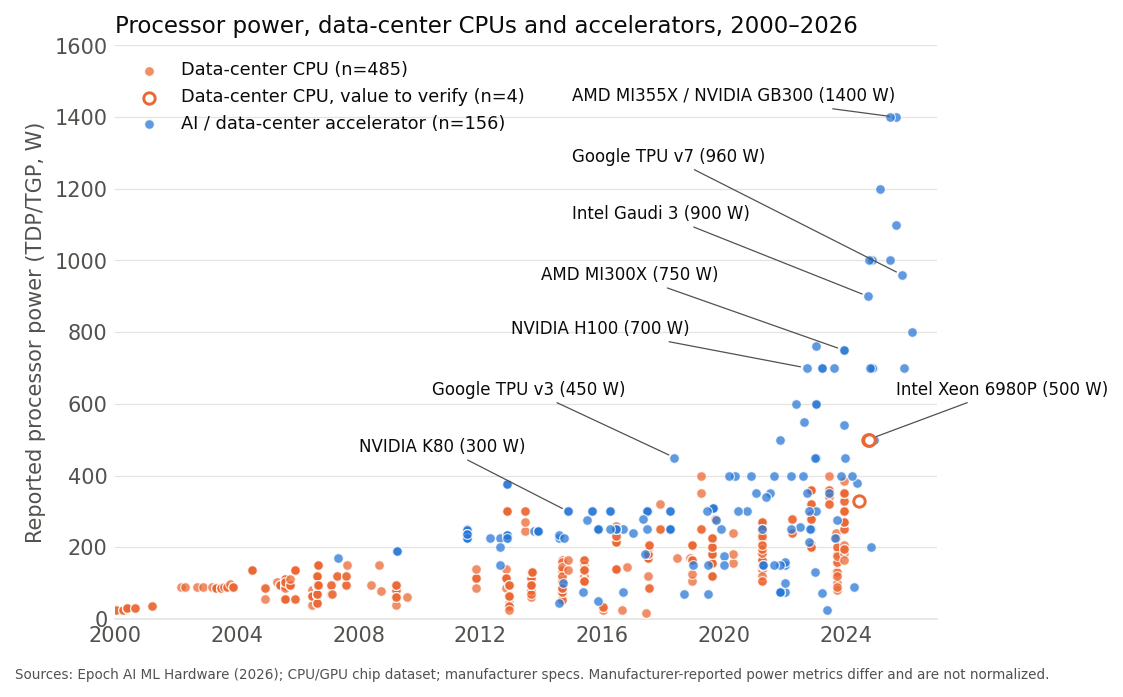

In [4]:
# Selected parts to label: one or two per vendor, spread across the period.
# Text sits at fixed positions in the empty upper-left region, with leader lines to the point.
LABELS = {  # product -> (label, text x, text y, horizontal alignment)
    'NVIDIA GB300 (Blackwell Ultra)': ('AMD MI355X / NVIDIA GB300 (1400 W)', '2015-01-01', 1460, 'left'),
    'Google TPU v7 Ironwood': ('Google TPU v7 (960 W)', '2015-01-01', 1290, 'left'),
    'Intel Habana Gaudi3': ('Intel Gaudi 3 (900 W)', '2015-01-01', 1130, 'left'),
    'AMD Instinct MI300X': ('AMD MI300X (750 W)', '2014-01-01', 960, 'left'),
    'NVIDIA H100 SXM5 80GB': ('NVIDIA H100 (700 W)', '2013-01-01', 810, 'left'),
    'Google TPU v3': ('Google TPU v3 (450 W)', '2010-06-01', 640, 'left'),
    'NVIDIA Tesla K80': ('NVIDIA K80 (300 W)', '2008-01-01', 480, 'left'),
    'Intel Xeon 6980P': ('Intel Xeon 6980P (500 W)', '2025-09-01', 640, 'left'),
}

plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'axes.edgecolor': GRID,
                     'axes.labelcolor': TEXT_2, 'xtick.color': TEXT_2, 'ytick.color': TEXT_2})
fig, ax = plt.subplots(figsize=(7.5, 4.6), dpi=150)

for group, color in [('Data-center CPU', C_CPU), ('AI / data-center accelerator', C_ACCEL)]:
    d = procs[(procs['group'] == group) & ~procs['verify']]
    ax.scatter(d['date'], d['tdp_W'], s=22, color=color, alpha=0.75, edgecolor='white', linewidth=0.6,
               label=f'{group} (n={len(d)})', zorder=3)
    v = procs[(procs['group'] == group) & procs['verify']]
    if len(v):
        ax.scatter(v['date'], v['tdp_W'], s=30, facecolor='white', edgecolor=color, linewidth=1.4, zorder=4,
                   label=f'{group}, value to verify (n={len(v)})')

for name, (label, tx, ty, ha) in LABELS.items():
    row = procs[procs['product'] == name]
    if row.empty:
        continue
    x, y = row['date'].iloc[0], row['tdp_W'].iloc[0]
    ax.annotate(label, xy=(x, y), xytext=(pd.Timestamp(tx), ty), fontsize=8, color=TEXT, va='center', ha=ha,
                arrowprops=dict(arrowstyle='-', color=TEXT_2, lw=0.6, shrinkA=0, shrinkB=3))

ax.set_ylabel('Reported processor power (TDP/TGP, W)')
ax.set_xlim(pd.Timestamp('2000-01-01'), pd.Timestamp('2027-01-01'))
ax.set_ylim(0, 1600)
ax.xaxis.set_major_locator(mdates.YearLocator(4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.tick_params(length=0)
ax.legend(loc='upper left', frameon=False, fontsize=8.5, labelcolor=TEXT)
ax.set_title('Processor power, data-center CPUs and accelerators, 2000–2026', loc='left', fontsize=11, color=TEXT)
fig.text(0.01, 0.005, 'Sources: Epoch AI ML Hardware (2026); CPU/GPU chip dataset; manufacturer specs. '
         'Manufacturer-reported power metrics differ and are not normalized.', fontsize=6.5, color=TEXT_2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(OUT / 'fig2a_processor_power.pdf')
fig.savefig(OUT / 'fig2a_processor_power.png', dpi=200)
plt.show()